| **Nombre de la columna**              | **Descripción**                                                                                                                                                    |
|--------------------------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| `id`                                 | Identificador único para cada polígono (generalmente del lado Google, o un ID global del DataFrame).                                                              |
| `area_in_me`                         | Área estimada del polígono, posiblemente en metros (requiere verificación exacta de unidad).                                                                      |
| `confidence`                         | Valor de confianza en la detección o extracción del polígono (p.ej., si proviene de un modelo de segmentación).                                                   |
| `full_plus_`                         | Posible código de ubicación (plus code) o dirección asociada al polígono.                                                                                         |
| `longitude_`                         | Valor de coordenada longitudinal (posible metadato de ubicación).                                                                                                 |
| `area_m2`                            | Área en metros cuadrados (cálculo confirmado).                                                                                                                    |
| `geometry`                           | Columna con la geometría del polígono (tipo Polygon o MultiPolygon) utilizada por GeoPandas.                                                                       |
| `origen`                             | Fuente del polígono (e.g., "google", "catastro").                                                                                                                 |
| `UOI`                                | Métrica de “Unión sobre Intersección” (0 = sin superposición, 1 = superposición total), calculada entre el polígono de Google y el de Catastro.                  |
| `ObjectID`                           | Identificador del polígono de Catastro con el que se hace la comparación principal.                                                                               |
| `Index_uoi`                          | Índice auxiliar relacionado con la métrica de UOI (podría servir para jerarquizar o filtrar resultados).                                                          |
| `Hausdorff_Distance`                 | Distancia de Hausdorff entre el polígono de Google y el polígono Catastro más similar (0 indica máxima similitud).                                               |
| `Most_Similar_ObjectID`              | ID del polígono Catastro que se consideró más similar al de Google (normalmente el que obtiene menor Hausdorff Distance).                                        |
| `Centroid_Distance`                  | Distancia entre los centroides (Google y Catastro).                                                                                                               |
| `neighbors_count`                    | Conteo de polígonos vecinos en un rango predefinido (ej. 10m) alrededor del polígono de interés.                                                                  |
| `google_mbr_angle_deg`               | Ángulo (en grados) del rectángulo mínimo envolvente (MBR) para el polígono de Google.                                                                             |
| `google_mbr_direction`               | Dirección categórica (texto) asociada a la orientación del MBR de Google (ej. “N-S” o “E-O”).                                                                      |
| `catastro_mbr_angle_deg`             | Ángulo (en grados) del rectángulo mínimo envolvente para el polígono de Catastro.                                                                                 |
| `catastro_mbr_direction`             | Dirección categórica (texto) asociada a la orientación del MBR de Catastro.                                                                                       |
| `adjusted_catastro_mbr_angle`        | Ángulo MBR de Catastro ajustado (por ejemplo en 90°) para fines de comparación con el polígono de Google.                                                         |
| `angle_difference`                   | Diferencia angular final entre el MBR de Catastro (ya ajustado) y el de Google.                                                                                   |
| `num_intersections`                  | Número de polígonos de Catastro que el polígono de Google toca o intersecta.                                                                                     |
| `combined_area`                      | Área resultante de la unión de todos los polígonos Catastro que intersectan el polígono de Google.                                                                |
| `combined_UOI`                       | Métrica de “Unión sobre Intersección” calculada de manera combinada (con todos los polígonos Catastro que intersecta el polígono de Google).                      |
| `google_centroid_x`                  | Coordenada X del centroide del polígono de Google.                                                                                                                |
| `google_centroid_y`                  | Coordenada Y del centroide del polígono de Google.                                                                                                                |
| `catastro_centroid_x`                | Coordenada X del centroide del polígono de Catastro.                                                                                                              |
| `catastro_centroid_y`                | Coordenada Y del centroide del polígono de Catastro.                                                                                                              |
| `hausdorff_to_combined`              | Distancia de Hausdorff calculada considerando la forma combinada de todos los polígonos Catastro intersectados.                                                   |
| `classification_score`               | Puntaje de clasificación resultante (ej. de un modelo predictivo), usado para determinar si el polígono es "NUEVO" o "EXISTENTE".                                  |


# Preprocesamiento
1. Cargamos los datos 
2. Revisamos la distribución de las variables (no incluimos coordenadas)
3. Revisamos si tiene datos nulos
4. Seleccionamos las variables objetivo
5. Escalamos las variables
	1. Aplicar el Reemplazo de inf por el Percentil 99 en Variables Numéricas
	2. Reemplazar inf con max + 1
6. Revisamos la distribución de las variables objetivo
	1. Realizamos k-means para classification_score y Hausdorff_Distance
7. Dividimos los datos de entrenamiento
8. Entrenamos al modelo 
	1. Utilizamos un pipeline para encapsular el proceso
		1. StandarScaler
		2. LogisticRegression
	2. X_train, y_train
9. Extraemos el modelo de regresión logística
	1. modelo_regresion_logistica
10. Análisis detallado del modelo 
11. Guardar modelo
12. Curva ROC
13. Matriz de confusion
14. Repetir el proceso pero con PCA

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import pickle


import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc,  classification_report, confusion_matrix, accuracy_score

In [2]:
df_catastro = gpd.read_parquet("gdf_catastro.parquet")
df_google = gpd.read_parquet("gdf_google_actualizado.parquet")

In [3]:
print(df_google.head())

                         id  area_in_me  confidence     full_plus_  \
0  1_1_0fe0000000000000a9d2   12.842600      0.6875  67M8G7XQ+6HX5   
1  1_1_0fe00000000000036322   26.180901      0.6875  67M8G7XX+CW7J   
2  1_1_0fe0000000000003764b   43.927399      0.6875  67M8G8M5+7MP3   
3  1_1_0fe0000000000003eca6   22.324301      0.6875  67M8G7HX+MMQ2   
4  1_1_0fe00000000000045b2e   28.755699      0.6875  67M8G8H4+76PP   

                                          longitude_  area_m2  \
0  { "coordinates": [ -73.711001, 3.548102 ], "ty...  12.7971   
1  { "coordinates": [ -73.700209, 3.548544 ], "ty...  26.0658   
2  { "coordinates": [ -73.690801, 3.533200 ], "ty...  43.7257   
3  { "coordinates": [ -73.700776, 3.529205 ], "ty...  22.2435   
4  { "coordinates": [ -73.694417, 3.528215 ], "ty...  28.6599   

                                            geometry  origen       UOI  \
0  POLYGON ((1040723.444 884112.962, 1040724.465 ...  google  0.073438   
1  POLYGON ((1041925.024 884157.256, 104

In [4]:
columnas_corr = [
    "area_in_me",                # Área (métrica)
    "confidence",                # Nivel de confianza
    "area_m2",                   # Área en metros cuadrados
    "UOI",                       # Indicador de superposición
    "Hausdorff_Distance",        # Distancia de Hausdorff (diferencia en forma)
    "Centroid_Distance",         # Distancia entre centroides
    "neighbors_count",           # Conteo de vecinos
    "google_mbr_angle_deg",      # Ángulo del MBR (Google)
    "catastro_mbr_angle_deg",    # Ángulo del MBR (Catastro)
    "adjusted_catastro_mbr_angle",  # Ángulo ajustado del MBR de Catastro
    "angle_difference",          # Diferencia de ángulo entre los polígonos
    "num_intersections",         # Número de intersecciones
    "combined_area",             # Área combinada (si es relevante)
    "combined_UOI",              # UOI combinado
    "google_centroid_x",         # Coordenada X del centroide de Google
    "google_centroid_y",         # Coordenada Y del centroide de Google
    "catastro_centroid_x",       # Coordenada X del centroide de Catastro
    "catastro_centroid_y",       # Coordenada Y del centroide de Catastro
    "hausdorff_to_combined",     # Distancia de Hausdorff combinada
    "classification_score"       # Puntaje de clasificación
]

# Crear un DataFrame con solo las columnas seleccionadas
df_corr = df_google[columnas_corr].copy()

# Calcular la matriz de correlación
corr_matrix = df_corr.corr()

print("Matriz de correlación:")
print(corr_matrix)

Matriz de correlación:
                             area_in_me  confidence   area_m2       UOI  \
area_in_me                     1.000000    0.317649  1.000000  0.090267   
confidence                     0.317649    1.000000  0.317651  0.088609   
area_m2                        1.000000    0.317651  1.000000  0.090264   
UOI                            0.090267    0.088609  0.090264  1.000000   
Hausdorff_Distance             0.324166   -0.037040  0.324167 -0.566245   
Centroid_Distance              0.045445   -0.139858  0.045443  0.063368   
neighbors_count                0.497623   -0.011393  0.497625  0.327390   
google_mbr_angle_deg           0.120626   -0.015886  0.120624  0.021060   
catastro_mbr_angle_deg         0.010668    0.059826  0.010671 -0.187583   
adjusted_catastro_mbr_angle    0.010668    0.059826  0.010671 -0.187583   
angle_difference               0.105016   -0.067345  0.105012  0.167293   
num_intersections              0.497623   -0.011393  0.497625  0.327390   
co

### **Variables Dependientes**
- classification_score
- Hausdorff_Distance
- combined_area
- combined_UOI
- google_mbr_angle_deg
- catastro_mbr_angle_deg
- adjusted_catastro_mbr_angle
- UOI
- hausdorff_to_combined

### **Variables Independientes**
- Centroid_Distance
- neighbors_count
- angle_difference
- area_in_me
- area_m2
- google_centroid_x
- google_centroid_y
- catastro_centroid_x
- catastro_centroid_y



In [5]:
print("Columnas en df_google:", df_google.columns)
print("Columnas en df_catastro:", df_catastro.columns)

Columnas en df_google: Index(['id', 'area_in_me', 'confidence', 'full_plus_', 'longitude_', 'area_m2',
       'geometry', 'origen', 'UOI', 'ObjectID', 'Index_uoi',
       'Hausdorff_Distance', 'Most_Similar_ObjectID', 'Centroid_Distance',
       'neighbors_count', 'google_mbr_angle_deg', 'google_mbr_direction',
       'catastro_mbr_angle_deg', 'catastro_mbr_direction',
       'adjusted_catastro_mbr_angle', 'angle_difference', 'num_intersections',
       'combined_area', 'combined_UOI', 'google_centroid_x',
       'google_centroid_y', 'catastro_centroid_x', 'catastro_centroid_y',
       'hausdorff_to_combined', 'classification_score'],
      dtype='object')
Columnas en df_catastro: Index(['FID_U_CONS', 'CODIGO', 'TERRENO_CO', 'TIPO_CONST', 'TIPO_DOMIN',
       'NUMERO_PIS', 'NUMERO_SOT', 'NUMERO_MEZ', 'NUMERO_SEM', 'ETIQUETA',
       'IDENTIFICA', 'CODIGO_EDI', 'CODIGO_ANT', 'USUARIO_LO', 'FECHA_LOG',
       'GLOBALID_S', 'SHAPE_Leng', 'SHAPE_Area', 'codigo_mun', 'CODIGO_DEP',
       'F

In [6]:
df_google['origen'].value_counts()

origen
google    18299
Name: count, dtype: int64

### verificamos que columnas son iguales

In [7]:
# Obtener los nombres de las columnas en cada dataset
columnas_google = set(df_google.columns)
columnas_catastro = set(df_catastro.columns)

# Encontrar las columnas que existen en ambos datasets
columnas_comunes = columnas_google.intersection(columnas_catastro)
print("Columnas en común:", columnas_comunes)


Columnas en común: {'geometry'}


In [8]:
df_google.dtypes

id                               object
area_in_me                      float64
confidence                      float64
full_plus_                       object
longitude_                       object
area_m2                         float64
geometry                       geometry
origen                           object
UOI                             float64
ObjectID                        float64
Index_uoi                       float64
Hausdorff_Distance              float64
Most_Similar_ObjectID           float64
Centroid_Distance               float64
neighbors_count                   int64
google_mbr_angle_deg            float64
google_mbr_direction             object
catastro_mbr_angle_deg          float64
catastro_mbr_direction           object
adjusted_catastro_mbr_angle     float64
angle_difference                float64
num_intersections                 int64
combined_area                   float64
combined_UOI                    float64
google_centroid_x               float64


In [9]:
df_google.shape

(18299, 30)

In [10]:
print(type(df_google))

<class 'geopandas.geodataframe.GeoDataFrame'>


### No existen datos nulos

In [11]:
# Porcentaje de valores nulos por columna
missing_values = df_google.isnull().mean() * 100
print(missing_values[missing_values > 0].sort_values(ascending=False))

# Visualizar las columnas con valores nulos
#plt.figure(figsize=(10, 6))
#missing_values[missing_values > 0].sort_values().plot(kind='barh', color='orange')
#plt.title("Porcentaje de valores faltantes por columna")
#plt.xlabel("Porcentaje")
#plt.ylabel("Columnas")
#plt.show()

Series([], dtype: float64)


### Revisaremos la distribucion de las variables

/home/fabian/miniconda3/envs/ml_env/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/fabian/miniconda3/envs/ml_env/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fabian/miniconda3/envs/ml_env/lib/python3.11/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/fabian/miniconda3/envs/ml_env/lib/py

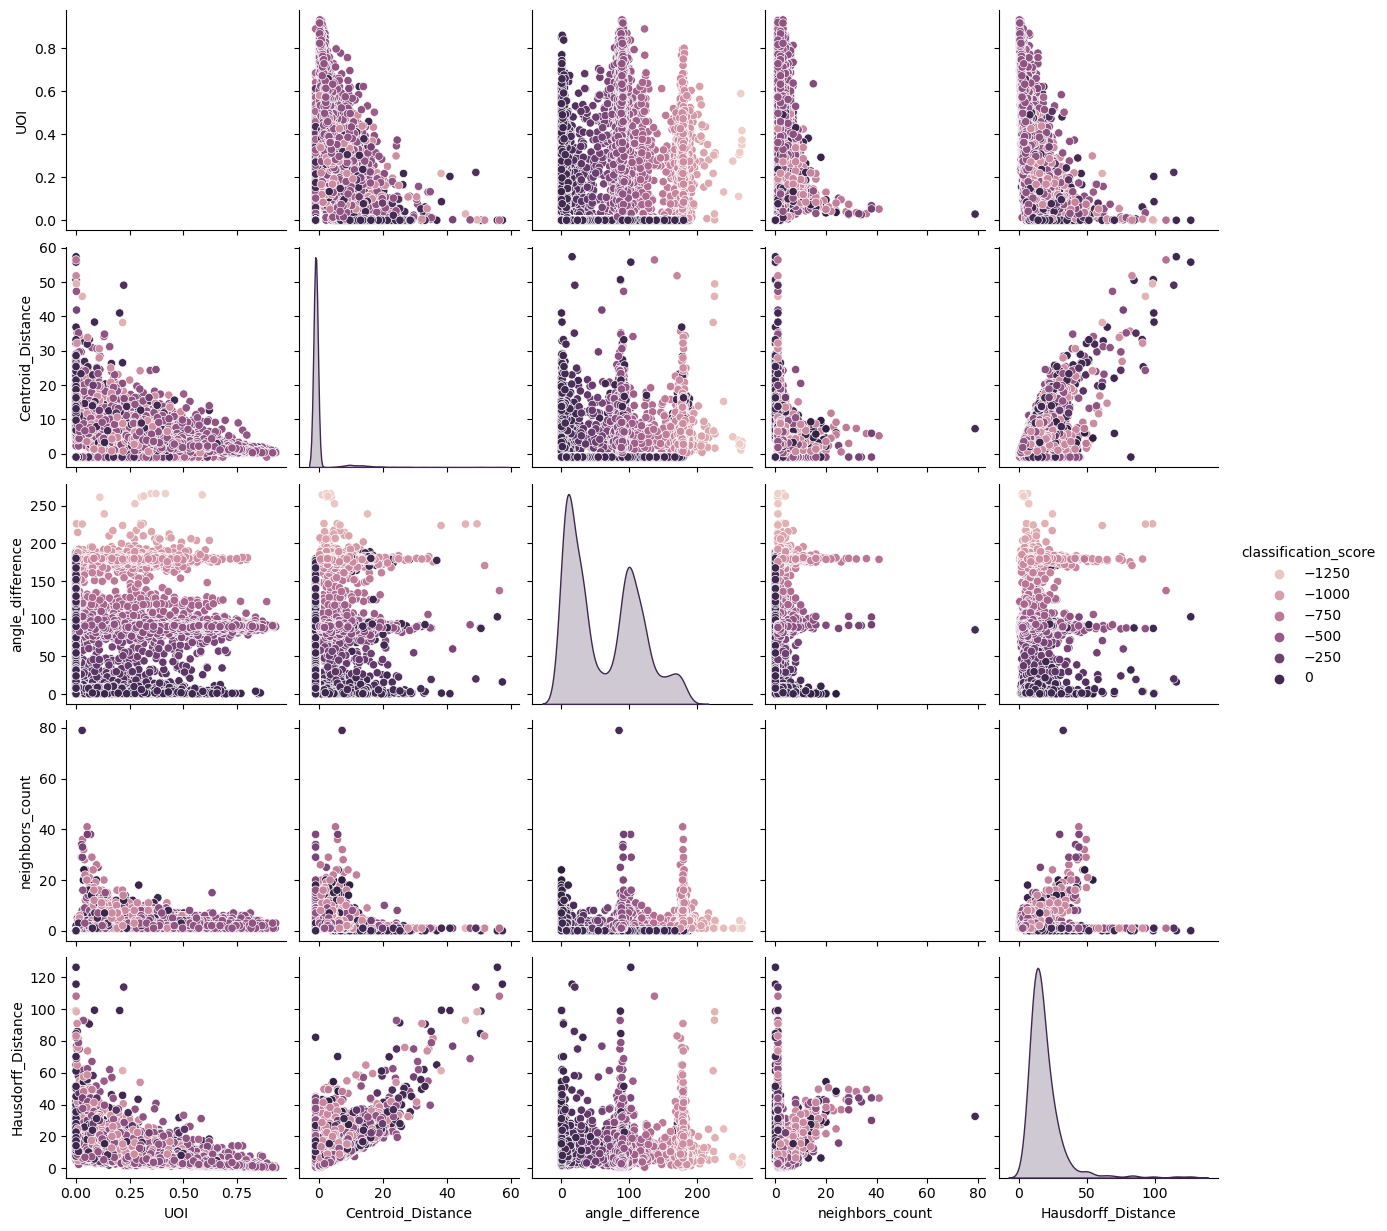

In [12]:
columnas_seleccionadas = [
    "geometry",
    "UOI",
    "Centroid_Distance",
    "angle_difference",
    "neighbors_count",
    "Hausdorff_Distance",
    "classification_score"]

# Seleccionar solo estas columnas (sin repetir classification_score)
sns.pairplot(df_google[columnas_seleccionadas], hue="classification_score")
plt.show()

### Columnas objetivo

In [13]:
# Crear una copia del DataFrame con solo esas columnas
df_reducido = df_google.copy()

In [14]:
print(df_reducido[["UOI", "Centroid_Distance", 
                   "angle_difference", "neighbors_count", 
                   "Hausdorff_Distance", "classification_score"]].corr())

                           UOI  Centroid_Distance  angle_difference  \
UOI                   1.000000           0.063368          0.167293   
Centroid_Distance     0.063368           1.000000          0.177182   
angle_difference      0.167293           0.177182          1.000000   
neighbors_count       0.327390           0.163737          0.219904   
Hausdorff_Distance   -0.566245           0.753223          0.041598   
classification_score -0.493747          -0.350823         -0.743118   

                      neighbors_count  Hausdorff_Distance  \
UOI                          0.327390           -0.566245   
Centroid_Distance            0.163737            0.753223   
angle_difference             0.219904            0.041598   
neighbors_count              1.000000            0.171960   
Hausdorff_Distance           0.171960            1.000000   
classification_score        -0.428690            0.028649   

                      classification_score  
UOI                          

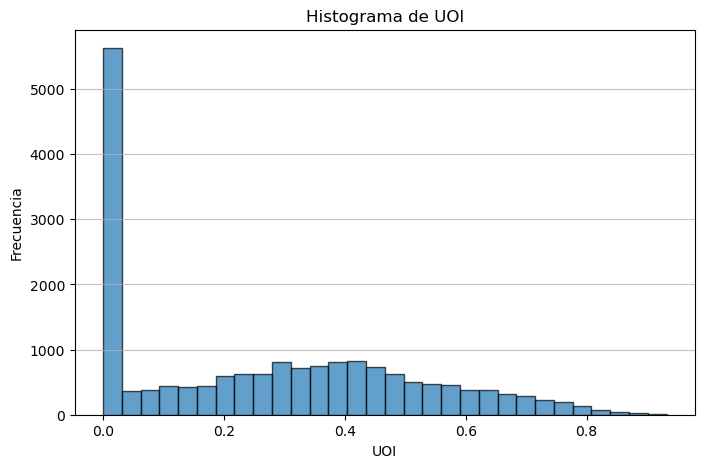

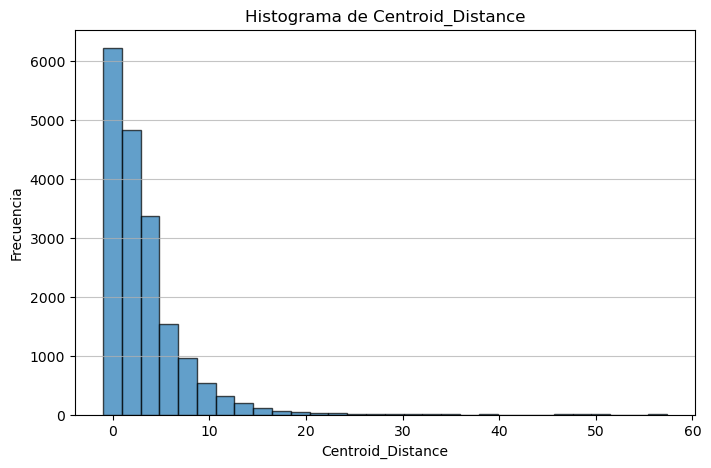

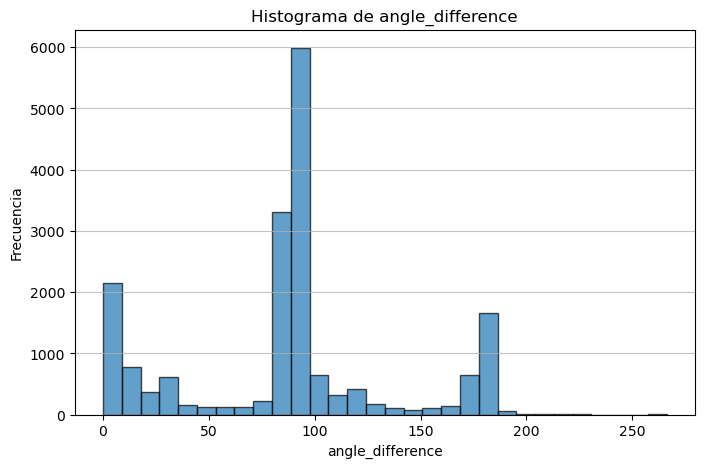

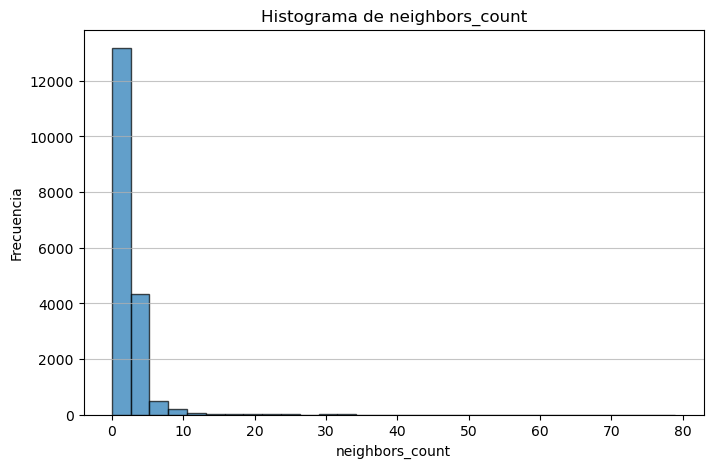

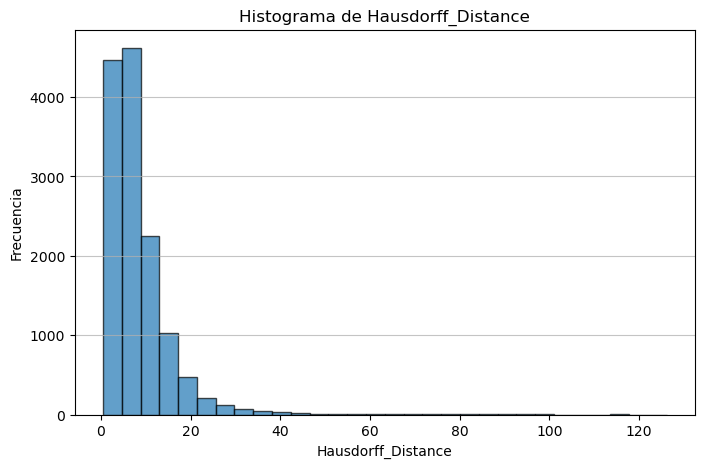

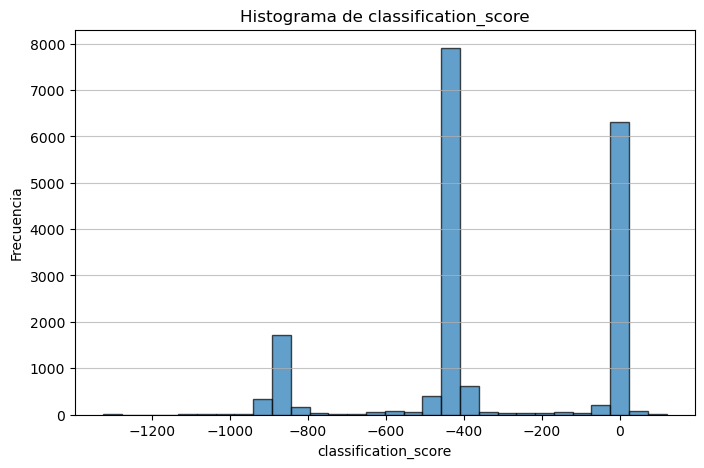

In [15]:
def plot_histograms(df, columns):
    """
    Grafica histogramas para cada columna numérica en la lista dada, asegurando que no haya valores infinitos.

    Parámetros:
    df (pd.DataFrame): DataFrame con los datos.
    columns (list): Lista de nombres de columnas a graficar.

    """
    for col in columns:
        if col in df.columns:
            # Reemplazar valores infinitos con el percentil 99 de la columna
            df_clean = df[col].replace([np.inf, -np.inf], np.nan).dropna()
            
            if df_clean.empty:
                print(f"La columna '{col}' no tiene valores válidos para graficar.")
                continue
            
            plt.figure(figsize=(8, 5))
            plt.hist(df_clean, bins=30, edgecolor='black', alpha=0.7)
            plt.title(f'Histograma de {col}')
            plt.xlabel(col)
            plt.ylabel('Frecuencia')
            plt.grid(axis='y', alpha=0.75)
            plt.show()
        else:
            print(f"La columna '{col}' no está en el DataFrame.")

# Uso de la función con la lista de columnas seleccionadas:
plot_histograms(df_reducido, ["UOI", "Centroid_Distance", "angle_difference", "neighbors_count", "Hausdorff_Distance", "classification_score"])


#### Establecer las columnas de variables numéricas y categóricas

#### Revision de valores unicos en dos variables de conteo

In [16]:
df_google['neighbors_count'].value_counts()

neighbors_count
0     5244
2     5059
1     2872
3     2516
4     1266
5      548
6      323
7      157
8      103
9       49
10      38
11      24
12      17
14      15
13      11
16      10
15       8
20       6
29       5
17       4
18       4
24       3
22       2
38       2
19       2
32       1
79       1
34       1
21       1
36       1
25       1
23       1
28       1
26       1
41       1
33       1
Name: count, dtype: int64

In [17]:
df_google['num_intersections'].value_counts()

num_intersections
0     5244
2     5059
1     2872
3     2516
4     1266
5      548
6      323
7      157
8      103
9       49
10      38
11      24
12      17
14      15
13      11
16      10
15       8
20       6
29       5
17       4
18       4
24       3
22       2
38       2
19       2
32       1
79       1
34       1
21       1
36       1
25       1
23       1
28       1
26       1
41       1
33       1
Name: count, dtype: int64

# Escalar las variables

#### Aplicar el Reemplazo de inf por el Percentil 99 en Variables Numéricas

In [18]:
# Buscar valores infinitos en X_train
print("Valores infinitos por columna en X_train:")
print(np.isinf(df_reducido[["UOI", "Centroid_Distance", 
                            "angle_difference", "neighbors_count",
                            "Hausdorff_Distance", "classification_score"]]).sum())

# Buscar valores muy grandes en X_train
print("\nValores mayores a 1e10 en X_train:")
print((df_reducido[["UOI", "Centroid_Distance", "angle_difference", 
                    "neighbors_count", "Hausdorff_Distance", 
                    "classification_score"]] 
       > 1e10).sum())

# Buscar valores nulos en X_train
print("\nValores nulos en X_train:")
print(df_reducido[["UOI", "Centroid_Distance", "angle_difference", 
                   "neighbors_count", "Hausdorff_Distance", 
                   "classification_score"]].isna().sum())

Valores infinitos por columna en X_train:
UOI                        0
Centroid_Distance          0
angle_difference           0
neighbors_count            0
Hausdorff_Distance      4895
classification_score       0
dtype: int64

Valores mayores a 1e10 en X_train:
UOI                        0
Centroid_Distance          0
angle_difference           0
neighbors_count            0
Hausdorff_Distance      4895
classification_score       0
dtype: int64

Valores nulos en X_train:
UOI                     0
Centroid_Distance       0
angle_difference        0
neighbors_count         0
Hausdorff_Distance      0
classification_score    0
dtype: int64


In [19]:
# Aplicar reemplazo en todas las variables numéricas donde es posible
for col in ["Hausdorff_Distance"]:
    max_value = np.percentile(df_reducido[col][df_reducido[col] != np.inf], 99)  # Obtener el percentil 99 evitando los inf
    df_reducido[col] = df_reducido[col].replace(np.inf, max_value)

print("Reemplazo de valores infinitos completado.")

Reemplazo de valores infinitos completado.


#### Reemplazar inf con max + 1

In [20]:
#for col in ["neighbors_count", "num_intersections"]:
#    max_value = df_reducido[col].max() + 1  # Obtener el valor más alto y sumarle 1
#    df_reducido[col] = df_reducido[col].replace(np.inf, max_value)  # Reemplazar inf con max + 1

### Revisamos la distribucion de las variables objetivo

#### classification_score Distribucion

/home/fabian/miniconda3/envs/ml_env/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


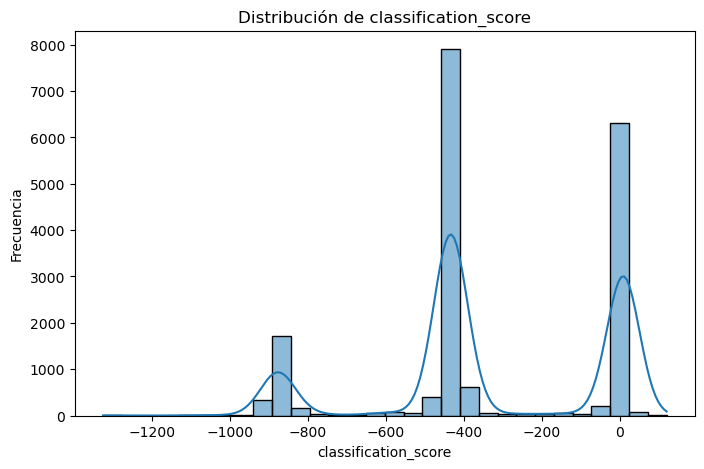

In [21]:
plt.figure(figsize=(8,5))
sns.histplot(df_reducido["classification_score"], bins=30, kde=True)
plt.title("Distribución de classification_score")
plt.xlabel("classification_score")
plt.ylabel("Frecuencia")
plt.show()

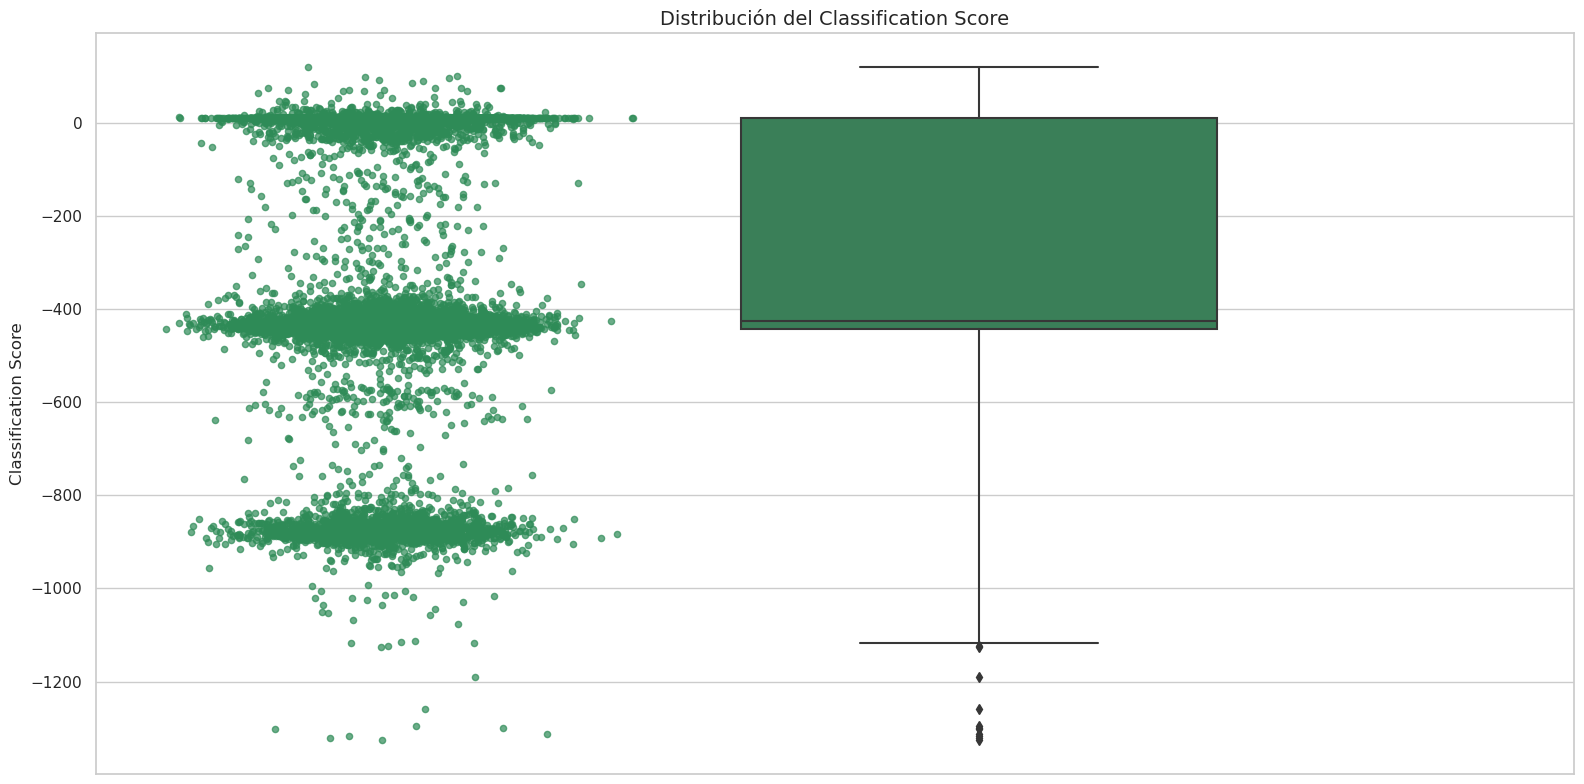

In [22]:
# Establecer el estilo con fondo claro
sns.set(style="whitegrid")

# Ajustar tamaño de la figura
plt.figure(figsize=(16, 8))

# Color personalizado
boxplot_color = "#2E8B57"  # Verde bosque
point_color = "#2E8B57"    # Mismo color para los puntos

# Dibujamos el boxplot
sns.boxplot(
    y=df_reducido["classification_score"],  
    color=boxplot_color,  
    width=0.4
)

# Generamos posiciones X aleatorias para los puntos (centrados en el boxplot)
xvals = np.random.normal(loc=0-0.5, scale=0.05, size=len(df_reducido["classification_score"]))

# Dibujamos los puntos sobre el boxplot para dispersarlos horizontalmente
plt.scatter(
    xvals, 
    df_reducido["classification_score"], 
    color=point_color,  
    alpha=0.7,       
    s=20             
)

# Etiquetas y título
plt.xlabel("")
plt.ylabel("Classification Score", fontsize=12)
plt.title("Distribución del Classification Score", fontsize=14)

plt.tight_layout()
plt.show()


#### Hausdorff_Distance distribucion

/home/fabian/miniconda3/envs/ml_env/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


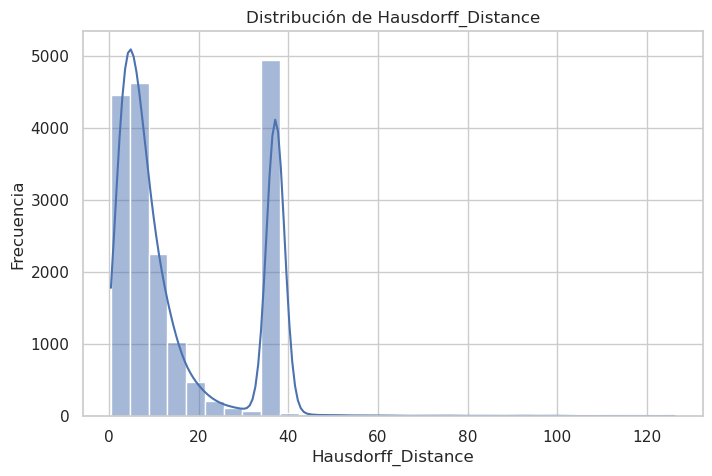

In [23]:
plt.figure(figsize=(8,5))
sns.histplot(df_reducido["Hausdorff_Distance"], bins=30, kde=True)
plt.title("Distribución de Hausdorff_Distance")
plt.xlabel("Hausdorff_Distance")
plt.ylabel("Frecuencia")
plt.show()

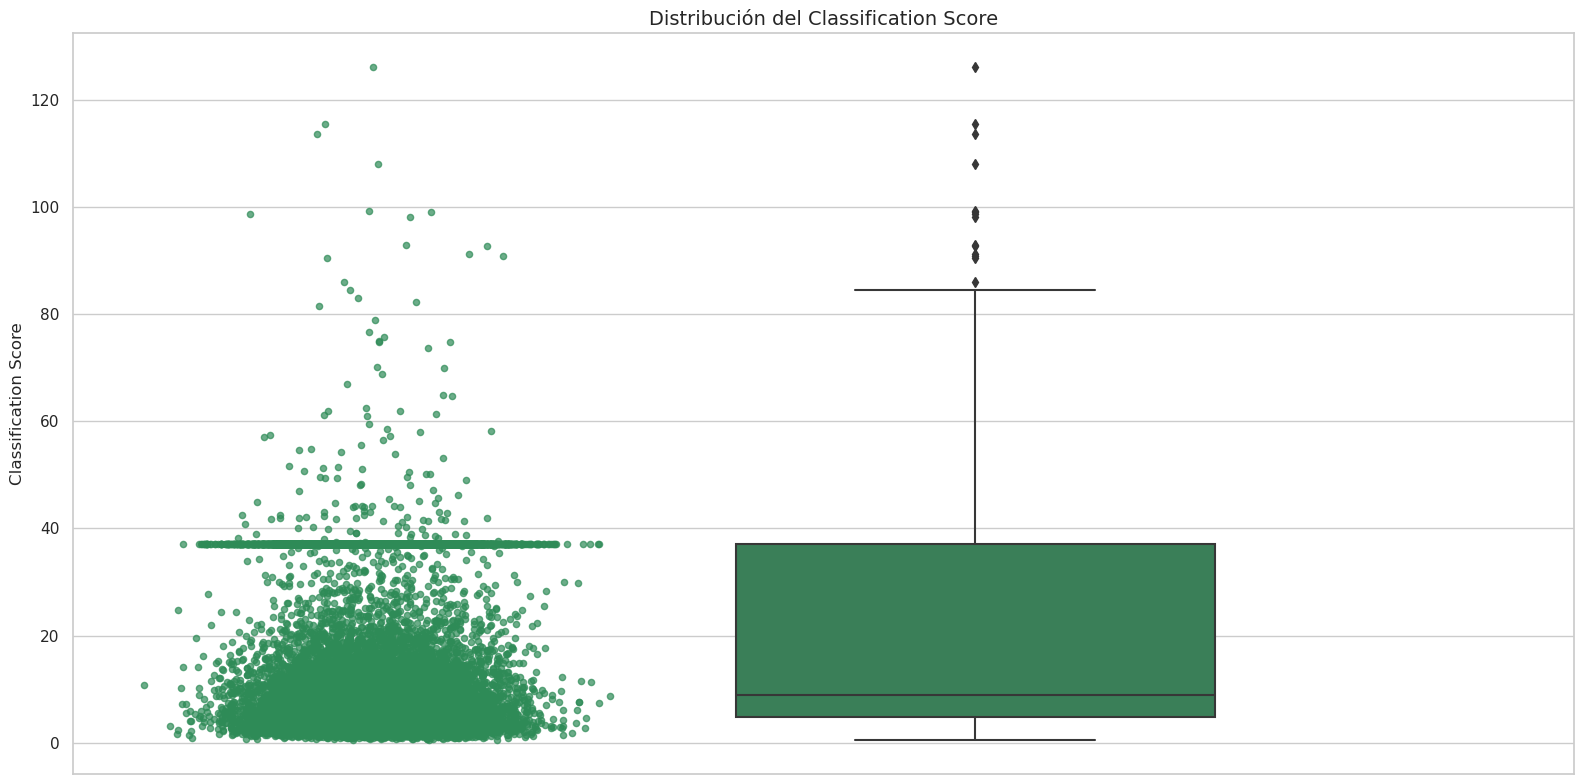

In [24]:
# Establecer el estilo con fondo claro
sns.set(style="whitegrid")

# Ajustar tamaño de la figura
plt.figure(figsize=(16, 8))

# Color personalizado
boxplot_color = "#2E8B57"  # Verde bosque
point_color = "#2E8B57"    # Mismo color para los puntos

# Dibujamos el boxplot
sns.boxplot(
    y=df_reducido["Hausdorff_Distance"],  
    color=boxplot_color,  
    width=0.4
)

# Generamos posiciones X aleatorias para los puntos (centrados en el boxplot)
xvals = np.random.normal(loc=0-0.5, scale=0.05, size=len(df_reducido["Hausdorff_Distance"]))

# Dibujamos los puntos sobre el boxplot para dispersarlos horizontalmente
plt.scatter(
    xvals, 
    df_reducido["Hausdorff_Distance"], 
    color=point_color,  
    alpha=0.7,       
    s=20             
)

# Etiquetas y título
plt.xlabel("")
plt.ylabel("Classification Score", fontsize=12)
plt.title("Distribución del Classification Score", fontsize=14)

plt.tight_layout()
plt.show()

### k-means para ver los grupos

In [25]:
from sklearn.cluster import KMeans

# Preparar los datos para clustering
classification_values = df_reducido[["classification_score"]].copy()

# Aplicar KMeans con 3 clusters
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
df_reducido["classification_group"] = kmeans.fit_predict(classification_values)

# Obtener los centros de cada grupo (valores representativos)
cluster_centers = np.sort(kmeans.cluster_centers_.flatten())
print("Centros de los clusters:", cluster_centers)

Centros de los clusters: [-876.56738489 -434.8151924     4.78134878]


In [26]:
# Ordenar los clusters identificados
sorted_clusters = np.sort(cluster_centers)

# Función para asignar etiquetas según los clusters detectados
def categorizar_classification(score):
    if score <= sorted_clusters[0]:
        return "Grupo 1"
    elif score <= sorted_clusters[1]:
        return "Grupo 2"
    else:
        return "Grupo 3"

# Aplicar la categorización
df_reducido["classification_category"] = df_reducido["classification_score"].apply(categorizar_classification)

# Verificar la cantidad de elementos en cada grupo
print(df_reducido["classification_category"].value_counts())

classification_category
Grupo 3    11253
Grupo 2     5796
Grupo 1     1250
Name: count, dtype: int64


In [27]:
# Obtener los grupos
grupo_1_center = cluster_centers[0]
grupo_2_center = cluster_centers[1]
grupo_3_center = cluster_centers[2]

# Calcular la desviación estándar dentro de cada grupo
std_1 = df_reducido[df_reducido["classification_group"] == 0]["classification_score"].std()
std_2 = df_reducido[df_reducido["classification_group"] == 1]["classification_score"].std()
std_3 = df_reducido[df_reducido["classification_group"] == 2]["classification_score"].std()

print(f"Desviación estándar de cada grupo:")
print(f"Grupo 1 ({grupo_1_center}): ± {std_1}")
print(f"Grupo 2 ({grupo_2_center}): ± {std_2}")
print(f"Grupo 3 ({grupo_3_center}): ± {std_3}")


Desviación estándar de cada grupo:
Grupo 1 (-876.5673848908083): ± 31.821248554682466
Grupo 2 (-434.8151923985225): ± 23.256799872683196
Grupo 3 (4.781348776311688): ± 44.64172406619608


In [28]:
# Definir umbrales de clasificación con desviación estándar
limite_1_2 = grupo_1_center + std_1  # Límite superior de Grupo 1
limite_2_3 = grupo_2_center + std_2  # Límite superior de Grupo 2

print(f"Límite Grupo 1 - Grupo 2: {limite_1_2}")
print(f"Límite Grupo 2 - Grupo 3: {limite_2_3}")

Límite Grupo 1 - Grupo 2: -844.7461363361258
Límite Grupo 2 - Grupo 3: -411.55839252583934


In [29]:
df_reducido.drop(columns=['classification_category','classification_group'], inplace=True)

### Creamos una capa para ver los datos de classificatio_score y Hausdorff_Distance

In [30]:
# Crear un nuevo GeoDataFrame con las columnas relevantes
gdf_qgis = df_google[["geometry", "classification_score", "Hausdorff_Distance"]]

# Guardar como GeoPackage
gdf_qgis.to_file("classification_comnbinada.gpkg", driver="GPKG")

print("Archivo generado. Cárgalo en QGIS para visualizarlo.")

Archivo generado. Cárgalo en QGIS para visualizarlo.


### Dividimos los datos para en entrenamiento

In [31]:
# Definir las variables predictoras y la variable objetivo
X = df_reducido[["UOI", "Centroid_Distance", "angle_difference", 
                 "neighbors_count", "Hausdorff_Distance"]]

# Convertir en binario (ejemplo: valores mayores a 0 son "nuevos", menores o iguales a 0 son "existentes")
y = (df_reducido["classification_score"] > 4).astype(int)  # Ahora tiene solo valores 0 y 1

# Dividir el conjunto de datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

#### Observamos los valores

In [32]:
y_train.head()

944      1
13708    0
8283     0
11035    0
4311     0
Name: classification_score, dtype: int64

In [33]:
y.value_counts()

classification_score
0    12511
1     5788
Name: count, dtype: int64

### Encapsulamos el proceso de entrenamiento y standarizacion de los datos

In [34]:
# Crear el Pipeline con escalado y regresión logística
pipeline_entrenamiento = Pipeline([
    ('scaler', StandardScaler()),  # Normalización de los datos
    ('classifier', LogisticRegression())  # Modelo de regresión logística
])

In [35]:
print(X_train.corr())

                         UOI  Centroid_Distance  angle_difference  \
UOI                 1.000000           0.064345          0.167443   
Centroid_Distance   0.064345           1.000000          0.179140   
angle_difference    0.167443           0.179140          1.000000   
neighbors_count     0.323972           0.161860          0.218399   
Hausdorff_Distance -0.791694          -0.195970         -0.241218   

                    neighbors_count  Hausdorff_Distance  
UOI                        0.323972           -0.791694  
Centroid_Distance          0.161860           -0.195970  
angle_difference           0.218399           -0.241218  
neighbors_count            1.000000           -0.390115  
Hausdorff_Distance        -0.390115            1.000000  


In [36]:
print(y_train.value_counts(normalize=True))

classification_score
0    0.685019
1    0.314981
Name: proportion, dtype: float64


In [37]:
# Entrenar el modelo con X_train (y_train no se escala)
pipeline_entrenamiento.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression())])

In [38]:
# Extraer el modelo de regresión logística del pipeline
modelo_regresion_logistica = pipeline_entrenamiento.named_steps['classifier']
#confirmacion del tipo de modelo almacenado
print(f'coeficientes:{modelo_regresion_logistica.coef_}')
print(f'intercepto:{modelo_regresion_logistica.intercept_}')
print(f'clases:{modelo_regresion_logistica.classes_}')
print(f'Iteraciones:{modelo_regresion_logistica.n_iter_}')

coeficientes:[[-1.20354407 -0.84966071 -1.24363291 -0.41317377  2.13004202]]
intercepto:[-1.58991545]
clases:[0 1]
Iteraciones:[12]


In [39]:
X_train.head(1)

,UOI,Centroid_Distance,angle_difference,neighbors_count,Hausdorff_Distance
944,0.0,-1.0,7.226327,0,37.135687


### Analisis detallado del modelo

In [40]:
X_train_sm = sm.add_constant(X_train)  # Añadir una constante para el término de intercepción
modelo_sm = sm.Logit(y_train, X_train_sm).fit()

# Mostrar el resumen del modelo que incluye la prueba de Wald
print(modelo_sm.summary())

Optimization terminated successfully.
         Current function value: 0.137082
         Iterations 9
                            Logit Regression Results                            
Dep. Variable:     classification_score   No. Observations:                14639
Model:                            Logit   Df Residuals:                    14633
Method:                             MLE   Df Model:                            5
Date:                  Fri, 07 Mar 2025   Pseudo R-squ.:                  0.7800
Time:                          10:18:48   Log-Likelihood:                -2006.7
converged:                         True   LL-Null:                       -9120.5
Covariance Type:              nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.4170      0.130      3.202      0.001       0.162  

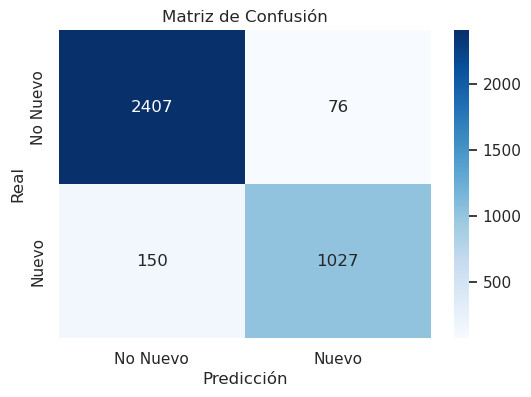

Accuracy: 0.9382513661202185
              precision    recall  f1-score   support

           0       0.94      0.97      0.96      2483
           1       0.93      0.87      0.90      1177

    accuracy                           0.94      3660
   macro avg       0.94      0.92      0.93      3660
weighted avg       0.94      0.94      0.94      3660



In [41]:
# Predecir en el conjunto de prueba
y_pred = pipeline_entrenamiento.predict(X_test)

# Calcular la matriz de confusión
cm = confusion_matrix(y_test, y_pred)

# Visualizar la matriz de confusión
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["No Nuevo", "Nuevo"], yticklabels=["No Nuevo", "Nuevo"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()
# Predicciones en el conjunto de prueba
y_pred = pipeline_entrenamiento.predict(X_test)

# Evaluar la precisión del modelo
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

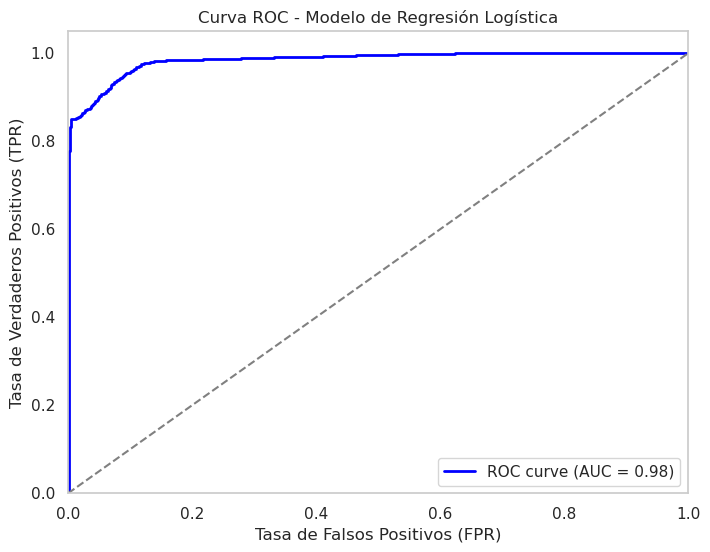

Área bajo la curva ROC (AUC): 0.9835


In [42]:

# Obtener las predicciones del modelo (probabilidades)
y_scores = pipeline_entrenamiento.predict_proba(X_test)[:, 1]  # Tomamos la probabilidad de clase positiva

# Calcular la Curva ROC
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)  # Área bajo la curva

# Graficar la Curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Línea de referencia
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Modelo de Regresión Logística')
plt.legend(loc="lower right")
plt.grid()
plt.show()


print(f"Área bajo la curva ROC (AUC): {roc_auc:.4f}")


#### Guardar el modelo 1* modelo

In [43]:
import pickle
# Guardar el resultado de la primera iteración en un archivo pickle
with open("rt1.pkl", 'wb') as archivo:
    pickle.dump((X_train, X_test, y_train, y_test, pipeline_entrenamiento), archivo)

In [44]:
# Cargar el resultado de la primera iteración
with open("rt1.pkl", 'rb') as archivo:
    X_train_1, X_test_1, y_train_1, y_test_1, pipeline_entrenamiento_1 = pickle.load(archivo)

In [45]:
# Crear una copia del DataFrame (GeoDataFrame) original (df_reducido)
gdf_qgis = df_reducido.copy()

# Agregar las predicciones al GeoDataFrame usando el pipeline entrenado
gdf_qgis["prediction"] = pipeline_entrenamiento.predict(X)

# Filtrar solo los predios clasificados como nuevos (prediction == 1)
gdf_nuevos = gdf_qgis[["geometry", "prediction"]]

# Convertir a GeoDataFrame, estableciendo el CRS a EPSG:3116
gdf_nuevos = gpd.GeoDataFrame(gdf_nuevos, geometry="geometry", crs="EPSG:3116")

# Guardar en un archivo GeoJSON
gdf_nuevos.to_file("predios_nuevos_1.json", driver="GeoJSON")

print("Archivo generado: 'predios_nuevos_1.json'. Ábrelo en QGIS para visualizar los predios nuevos.")

Archivo generado: 'predios_nuevos_1.json'. Ábrelo en QGIS para visualizar los predios nuevos.


In [46]:
# Crear una copia del DataFrame (GeoDataFrame) original (df_reducido)
gdf_qgis = df_reducido.copy()

# Agregar las predicciones al GeoDataFrame usando el pipeline entrenado
gdf_qgis["prediction"] = pipeline_entrenamiento.predict(X)

# Filtrar solo los predios clasificados como nuevos (prediction == 1)
gdf_nuevos = gdf_qgis[["geometry", "prediction"]]

# Convertir a GeoDataFrame, estableciendo el CRS a EPSG:3116
gdf_nuevos = gpd.GeoDataFrame(gdf_nuevos, geometry="geometry", crs="EPSG:3116")

# Guardar el GeoDataFrame en un archivo pickle
with open("predios_nuevos_1.pkl", "wb") as file:
    pickle.dump(gdf_nuevos, file)

print("Archivo generado: 'predios_nuevos_1.pkl'.")

Archivo generado: 'predios_nuevos_1.pkl'.


In [47]:
print(gdf_nuevos.crs)  # Capa creada
print(df_catastro.crs)  # Capa de catastro

EPSG:3116
{"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "MAGNA-SIRGAS / Colombia Bogota zone", "base_crs": {"name": "MAGNA-SIRGAS", "datum": {"type": "GeodeticReferenceFrame", "name": "Marco Geocentrico Nacional de Referencia", "ellipsoid": {"name": "GRS 1980", "semi_major_axis": 6378137, "inverse_flattening": 298.257222101}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degree"}]}, "id": {"authority": "EPSG", "code": 4686}}, "conversion": {"name": "Colombia MAGNA Bogota zone", "method": {"name": "Transverse Mercator", "id": {"authority": "EPSG", "code": 9807}}, "parameters": [{"name": "Latitude of natural origin", "value": 4.59620041666667, "unit": "degree", "id": {"authority": "EPSG", "code": 8801}}, {"name": "Longitude of natural origin", "value

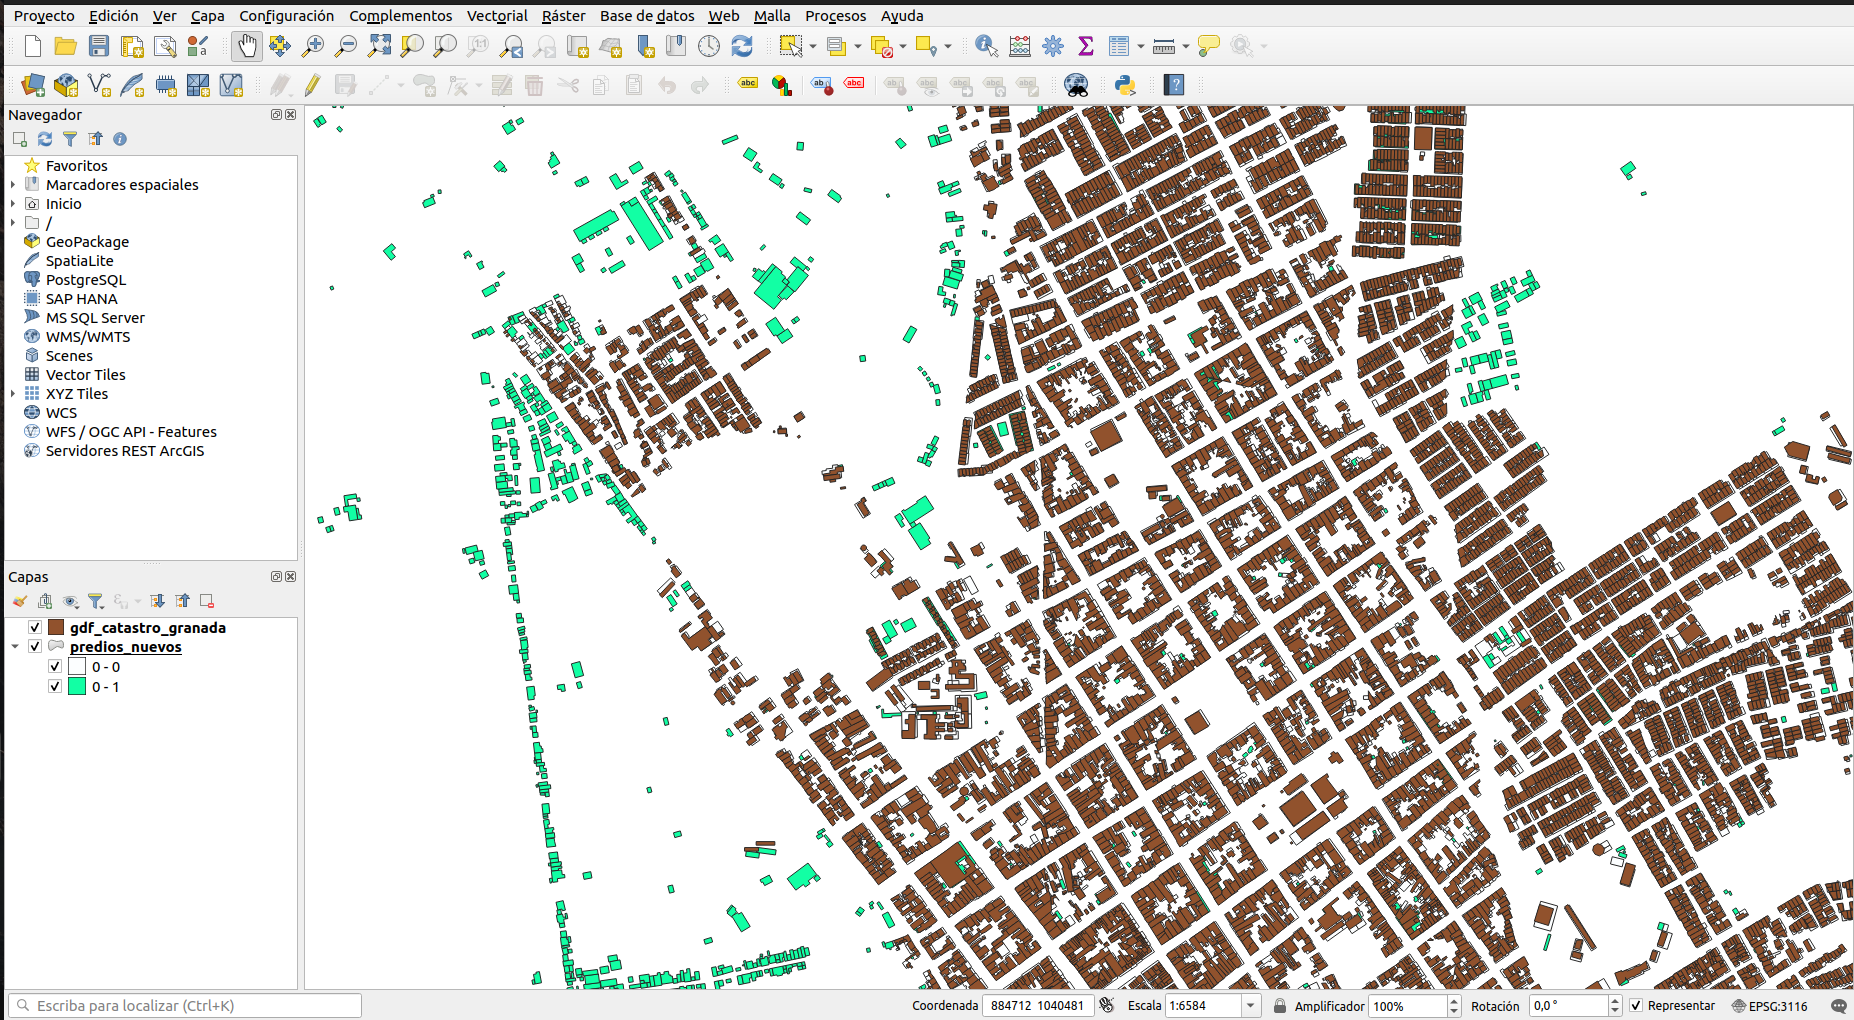

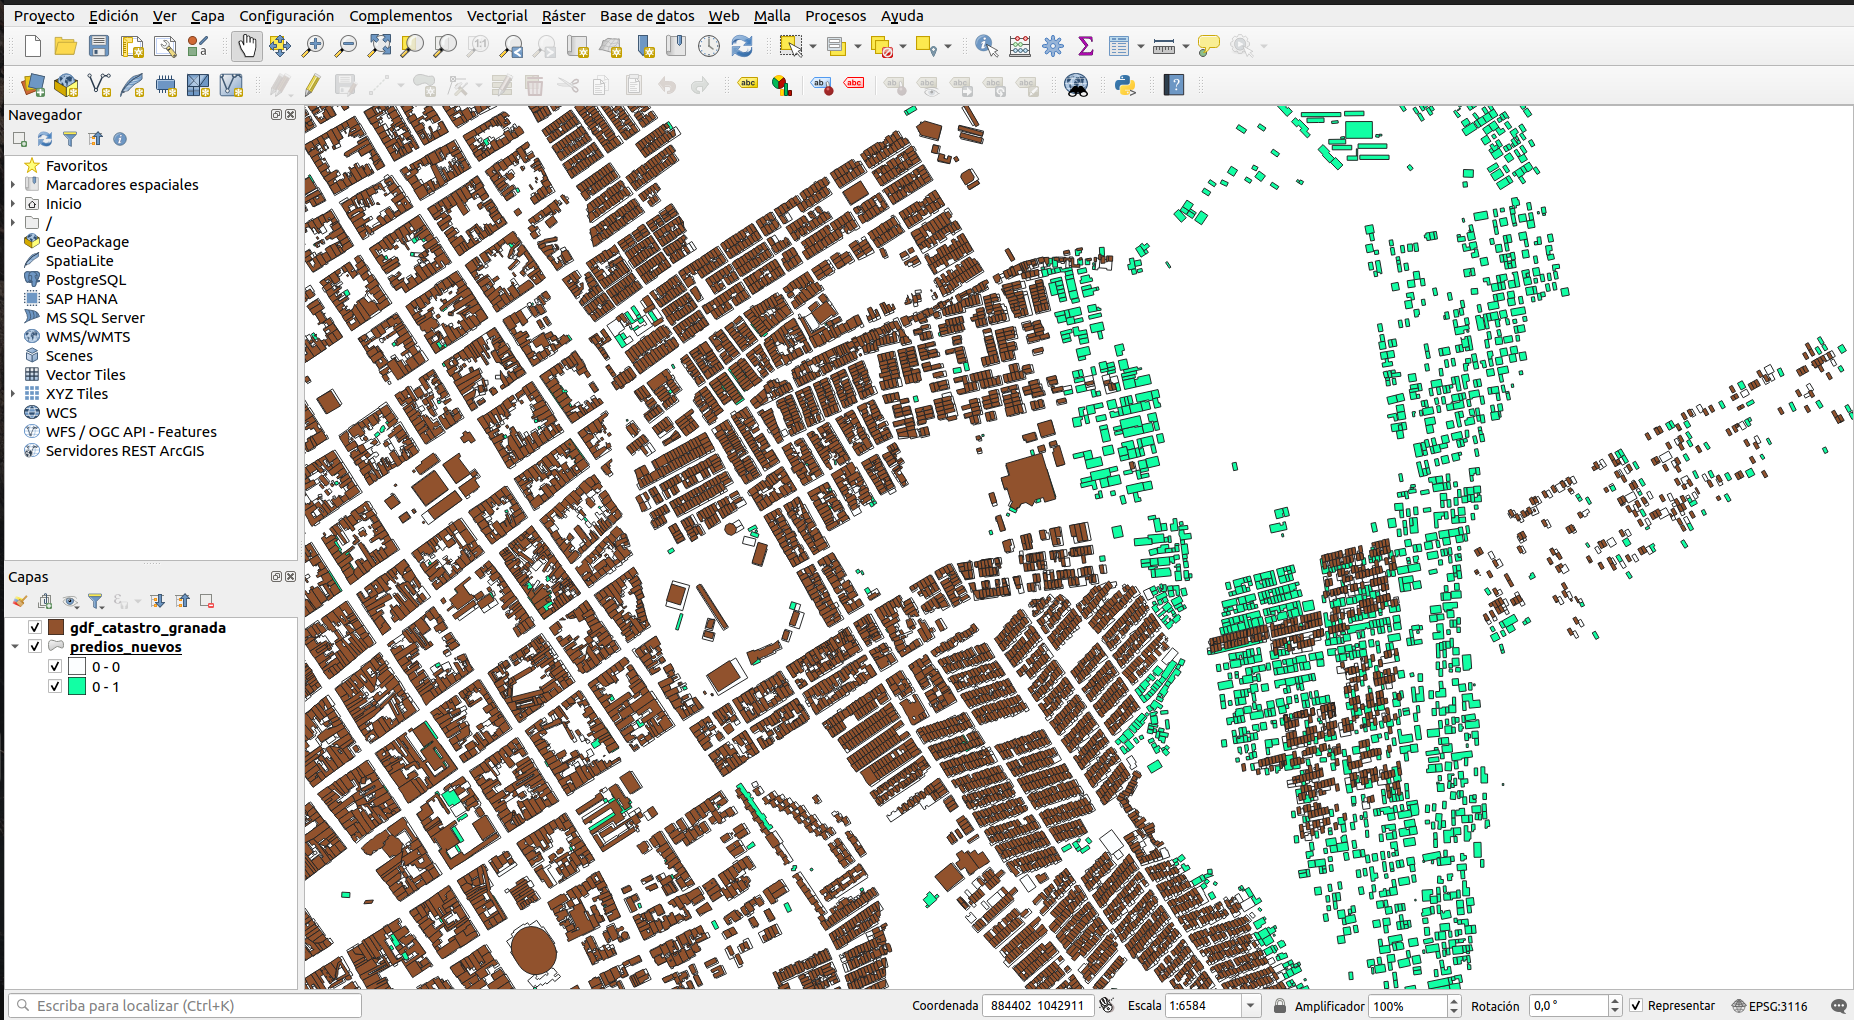

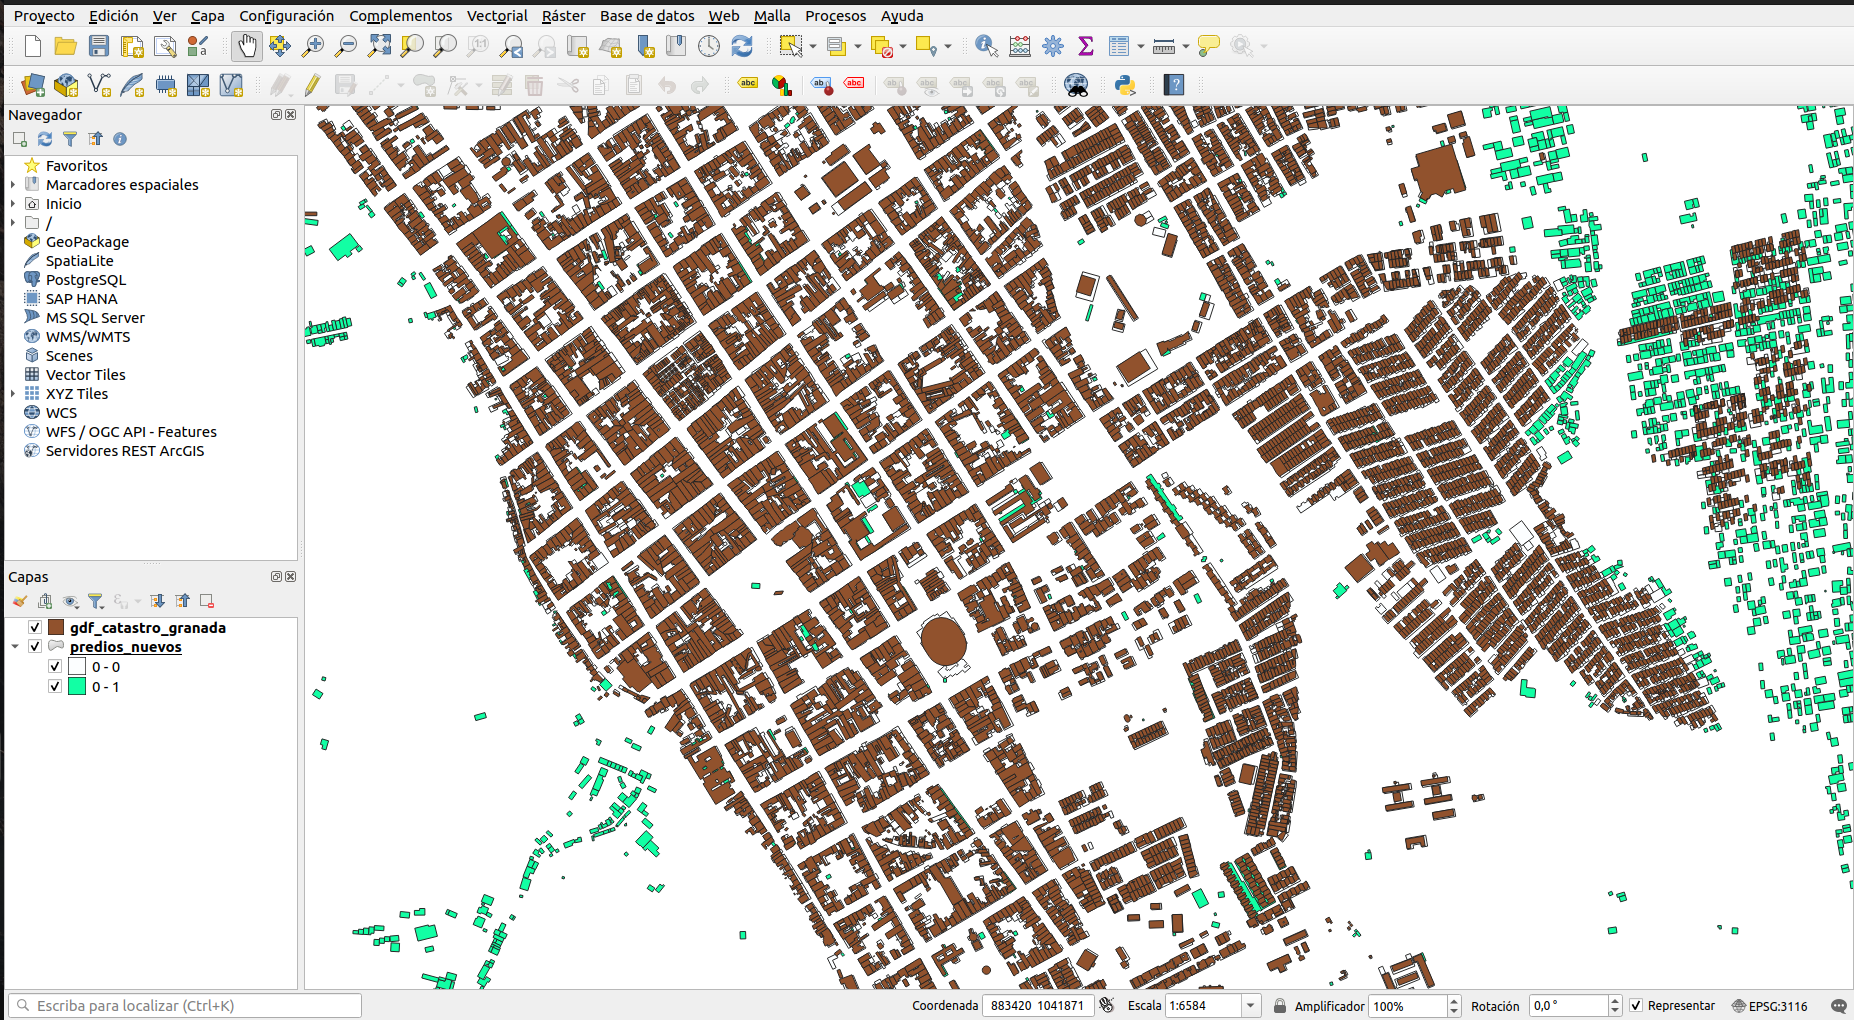

## Prueba 2

### Hausdorff_Distance

In [48]:
df_2 = df_google.copy()

In [49]:
# Definir las variables predictoras y la variable objetivo
X = df_2[["UOI", "Centroid_Distance", "angle_difference", 
             "neighbors_count", "classification_score"]]
# Convertir en binario (ejemplo: valores mayores a 0 son "nuevos", menores o iguales a 0 son "existentes")
y = (df_2["Hausdorff_Distance"] > 9).astype(int)  # Ahora tiene solo valores 0 y 1

# Dividir el conjunto de datos en conjuntos de entrenamiento y prueba
X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(X, y, test_size=0.2, random_state=0)

In [50]:
print(y_train_1.value_counts(normalize=True))

Hausdorff_Distance
0    0.506319
1    0.493681
Name: proportion, dtype: float64


In [51]:
print(X_train_1.corr())

                           UOI  Centroid_Distance  angle_difference  \
UOI                   1.000000           0.064345          0.167443   
Centroid_Distance     0.064345           1.000000          0.179140   
angle_difference      0.167443           0.179140          1.000000   
neighbors_count       0.323972           0.161860          0.218399   
classification_score -0.490650          -0.352016         -0.746756   

                      neighbors_count  classification_score  
UOI                          0.323972             -0.490650  
Centroid_Distance            0.161860             -0.352016  
angle_difference             0.218399             -0.746756  
neighbors_count              1.000000             -0.422377  
classification_score        -0.422377              1.000000  


In [52]:
# Entrenar el modelo con X_train (y_train no se escala)
pipeline_entrenamiento.fit(X_train_1, y_train_1)

Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', LogisticRegression())])

In [53]:
# Extraer el modelo de regresión logística del pipeline
modelo_regresion_logistica_1 = pipeline_entrenamiento.named_steps['classifier']
#confirmacion del tipo de modelo almacenado
print(f'coeficientes:{modelo_regresion_logistica_1.coef_}')
print(f'intercepto:{modelo_regresion_logistica_1.intercept_}')
print(f'clases:{modelo_regresion_logistica_1.classes_}')
print(f'Iteraciones:{modelo_regresion_logistica_1.n_iter_}')

coeficientes:[[-2.29499882  1.24597525  4.61151077  0.24594222  5.65996851]]
intercepto:[0.93237329]
clases:[0 1]
Iteraciones:[14]


In [54]:
X_train_1.head(1)

,UOI,Centroid_Distance,angle_difference,neighbors_count,classification_score
944,0.0,-1.0,7.226327,0,10.0


### Analisis detallado del modelo

In [55]:
X_train_sm_1 = sm.add_constant(X_train_1)  # Añadir una constante para el término de intercepción
modelo_sm_1 = sm.Logit(y_train_1, X_train_sm_1).fit()

# Mostrar el resumen del modelo que incluye la prueba de Wald
print(modelo_sm_1.summary())

Optimization terminated successfully.
         Current function value: 0.289477
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:     Hausdorff_Distance   No. Observations:                14639
Model:                          Logit   Df Residuals:                    14633
Method:                           MLE   Df Model:                            5
Date:                Fri, 07 Mar 2025   Pseudo R-squ.:                  0.5823
Time:                        10:18:49   Log-Likelihood:                -4237.6
converged:                       True   LL-Null:                       -10146.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.7258      0.089      8.146      0.000       0.551       0.90

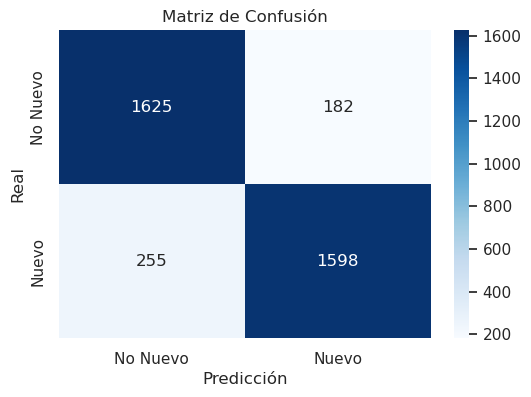

Accuracy: 0.8806010928961748
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1807
           1       0.90      0.86      0.88      1853

    accuracy                           0.88      3660
   macro avg       0.88      0.88      0.88      3660
weighted avg       0.88      0.88      0.88      3660



In [56]:
# Predecir en el conjunto de prueba
y_pred_1 = pipeline_entrenamiento.predict(X_test_1)

# Calcular la matriz de confusión
cm = confusion_matrix(y_test_1, y_pred_1)

# Visualizar la matriz de confusión
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["No Nuevo", "Nuevo"],
            yticklabels=["No Nuevo", "Nuevo"])
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()
# Predicciones en el conjunto de prueba
y_pred_1 = pipeline_entrenamiento.predict(X_test_1)

# Evaluar la precisión del modelo
print("Accuracy:", accuracy_score(y_test_1, y_pred_1))
print(classification_report(y_test_1, y_pred_1))

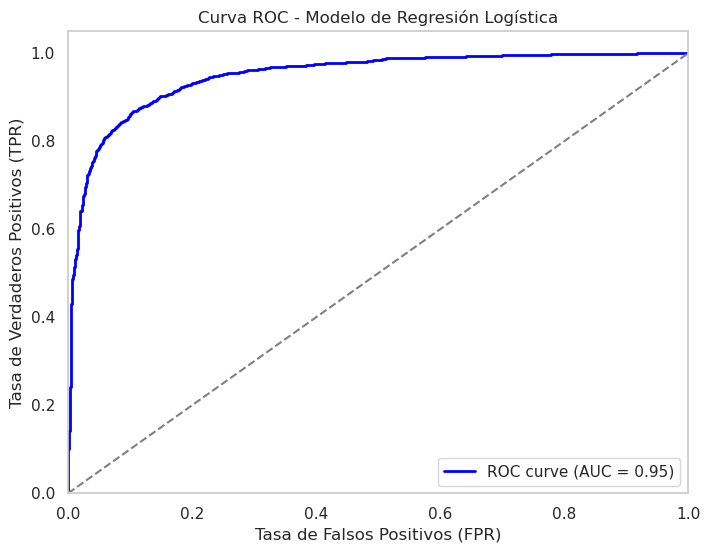

Área bajo la curva ROC (AUC): 0.9494


In [57]:
# Obtener las predicciones del modelo (probabilidades)
y_scores_1 = pipeline_entrenamiento.predict_proba(X_test_1)[:, 1]  # Tomamos la probabilidad de clase positiva

# Calcular la Curva ROC
fpr, tpr, thresholds = roc_curve(y_test_1, y_scores_1)
roc_auc = auc(fpr, tpr)  # Área bajo la curva

# Graficar la Curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')  # Línea de referencia
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Modelo de Regresión Logística')
plt.legend(loc="lower right")
plt.grid()
plt.show()

print(f"Área bajo la curva ROC (AUC): {roc_auc:.4f}")

In [58]:
# Guardar el resultado de la primera iteración en un archivo pickle
with open("rt2.pkl", 'wb') as archivo:
    pickle.dump((X_train_1, X_test_1, y_train_1, y_test_1, pipeline_entrenamiento), archivo)

In [59]:
# Cargar el resultado de la primera iteración
with open("rt2.pkl", 'rb') as archivo:
    X_train_1, X_test_1, y_train_1, y_test_1, pipeline_entrenamiento_1 = pickle.load(archivo)

In [60]:
# Crear una copia del DataFrame (GeoDataFrame) 
gdf_qgis = df_2.copy()

# Agregar las predicciones al GeoDataFrame usando el pipeline entrenado
gdf_qgis["prediction"] = pipeline_entrenamiento.predict(X)

# Filtrar solo los predios clasificados como nuevos (prediction == 1)
gdf_nuevos = gdf_qgis[["geometry", "prediction"]]

gdf_nuevos = gpd.GeoDataFrame(gdf_nuevos, geometry="geometry", crs="EPSG:3116")

# Guardar en un archivo GeoJSON
gdf_nuevos.to_file("predios_nuevos_2.json", driver="GeoJSON")

print("Archivo generado: 'predios_nuevos.json'. Ábrelo en QGIS para visualizar los predios nuevos.")

Archivo generado: 'predios_nuevos.json'. Ábrelo en QGIS para visualizar los predios nuevos.


In [61]:
# Crear una copia del DataFrame (GeoDataFrame) original (df_reducido)
gdf_qgis = df_2.copy()

# Agregar las predicciones al GeoDataFrame usando el pipeline entrenado
gdf_qgis["prediction"] = pipeline_entrenamiento.predict(X)

# Filtrar solo los predios clasificados como nuevos (prediction == 1)
gdf_nuevos = gdf_qgis[["geometry", "prediction"]]

# Convertir a GeoDataFrame, estableciendo el CRS a EPSG:3116
gdf_nuevos = gpd.GeoDataFrame(gdf_nuevos, geometry="geometry", crs="EPSG:3116")

# Guardar el GeoDataFrame en un archivo pickle
with open("predios_nuevos_2.pkl", "wb") as file:
    pickle.dump(gdf_nuevos, file)

print("Archivo generado: 'predios_nuevos_2.pkl'.")

Archivo generado: 'predios_nuevos_2.pkl'.


# Comparacion de los modelos

In [66]:
# Ajustar el primer modelo
X_train_sm = sm.add_constant(X_train)  # Añadir la constante
modelo_sm = sm.Logit(y_train, X_train_sm).fit()
print("Resumen del primer modelo:")
print(modelo_sm.summary())

# Ajustar el segundo modelo
X_train_sm_1 = sm.add_constant(X_train_1)  # Añadir la constante
modelo_sm_1 = sm.Logit(y_train_1, X_train_sm_1).fit()
print("\nResumen del segundo modelo:")
print(modelo_sm_1.summary())





Optimization terminated successfully.
         Current function value: 0.137082
         Iterations 9
Resumen del primer modelo:
                            Logit Regression Results                            
Dep. Variable:     classification_score   No. Observations:                14639
Model:                            Logit   Df Residuals:                    14633
Method:                             MLE   Df Model:                            5
Date:                  Fri, 07 Mar 2025   Pseudo R-squ.:                  0.7800
Time:                          10:22:33   Log-Likelihood:                -2006.7
converged:                         True   LL-Null:                       -9120.5
Covariance Type:              nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  0.4170      0.130      3.2

In [67]:
# Extraer las tablas resumen (coeficientes, errores, etc.) en formato DataFrame
df_modelo1 = modelo_sm.summary2().tables[1]
df_modelo2 = modelo_sm_1.summary2().tables[1]

# Renombrar columnas para identificar cada modelo
df_modelo1 = df_modelo1.rename(columns={
    'Coef.': 'Coef_Modelo1', 
    'Std.Err.': 'Std_Err_Modelo1', 
    'z': 'z_Modelo1', 
    'P>|z|': 'P_val_Modelo1', 
    '[0.025': 'CI_lower_Modelo1', 
    '0.975]': 'CI_upper_Modelo1'
})
df_modelo2 = df_modelo2.rename(columns={
    'Coef.': 'Coef_Modelo2', 
    'Std.Err.': 'Std_Err_Modelo2', 
    'z': 'z_Modelo2', 
    'P>|z|': 'P_val_Modelo2', 
    '[0.025': 'CI_lower_Modelo2', 
    '0.975]': 'CI_upper_Modelo2'
})
# Combinar ambos DataFrames para una comparación lado a lado
comparacion = pd.concat([df_modelo1, df_modelo2], axis=1)
print("\nComparación de coeficientes y errores estándar:")
print(comparacion)


Comparación de coeficientes y errores estándar:
                      Coef_Modelo1  Std_Err_Modelo1  z_Modelo1  P_val_Modelo1  \
const                     0.417035         0.130226   3.202380   1.362972e-03   
UOI                      -5.068647         0.333817 -15.183897   4.521072e-52   
Centroid_Distance        -0.200899         0.007743 -25.947565  1.937093e-148   
angle_difference         -0.024511         0.000895 -27.394916  3.152955e-165   
neighbors_count          -0.183150         0.016641 -11.005753   3.585089e-28   
Hausdorff_Distance        0.149427         0.004702  31.781705  1.158625e-221   
classification_score           NaN              NaN        NaN            NaN   

                      CI_lower_Modelo1  CI_upper_Modelo1  Coef_Modelo2  \
const                         0.161795          0.672274      0.725768   
UOI                          -5.722917         -4.414378     -9.344112   
Centroid_Distance            -0.216074         -0.185724      0.310197   
angle_

In [64]:
# Comparar algunas métricas globales de los modelos (por ejemplo, AIC y BIC)
print("\nMétricas globales de los modelos:")
print("Modelo 1 - AIC:", modelo_sm.aic, "BIC:", modelo_sm.bic)
print("Modelo 2 - AIC:", modelo_sm_1.aic, "BIC:", modelo_sm_1.bic)


Métricas globales de los modelos:
Modelo 1 - AIC: 4025.484613460072 BIC: 4071.0332803351007
Modelo 2 - AIC: 8487.299361437912 BIC: 8532.848028312941
